# Wheel parameter exploration

Broad exploratory analysis for `wheel_params.csv`: data quality, summaries, distributions, outlier flags, correlations, geometry-specific relationships, candidate derived dimensions, and modeling implications. The file currently has design inputs only, no measured prediction targets. Correlation is descriptive and does not imply causation.

Initial inspection finds 60 cases and 23 columns: 22 numeric design variables plus the `case_id` identifier. All fields are populated and IDs are unique. Several design controls use a limited number of repeated levels, while connector and radial geometry fields vary more continuously. With only 60 cases, any later predictive evaluation will have substantial uncertainty; keep that in mind when interpreting scores.

In [9]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'axes.labelsize': 9})
path = next((p for p in [Path('wheel_params.csv'), Path('../wheel_params.csv')] if p.is_file()), None)
if path is None: raise FileNotFoundError('Open from repository root or notebooks/; wheel_params.csv not found.')
df = pd.read_csv(path)
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = [c for c in df if c not in num_cols]
print(f'{path.resolve()} — {len(df)} rows × {len(df.columns)} columns ({len(num_cols)} numeric)')
display(df.head())

/home/remandey/my-programs/HMW-PREDICTION-MODELLING/wheel_params.csv — 60 rows × 23 columns (22 numeric)


,case_id,OD_mm,half_width_mm,tread_thk_mm,ring_OD_mm,ring_thk_mm,hub_OD_mm,hub_thk_mm,layers,radial_depth_mm,...,cell_angle_deg,cell_t_mm,cell_N,conn_s_mm,conn_s_inner_mm,conn_s_outer_mm,conn_angle_deg,total_cells,hex_regularity_pct,solidity_pct
0,HEX60_01,265,80,6.25,252.5,3.00,170,5.0,2,38.25,...,24.0,2.50,30,6.49,4.48,8.49,6.000,60,80.0,19.5
1,HEX60_02,225,75,5.75,213.5,2.75,145,3.5,2,31.50,...,26.0,1.50,31,5.75,4.15,7.35,5.806,62,81.0,13.7
2,HEX60_03,265,77,7.00,251.0,2.25,185,3.5,2,30.75,...,27.0,1.75,31,5.60,4.04,7.16,5.806,62,84.0,15.9
3,HEX60_04,280,75,7.00,266.0,2.75,200,5.0,2,30.25,...,28.0,1.50,32,6.09,4.61,7.58,5.625,64,87.0,13.6
4,HEX60_05,265,80,6.50,252.0,2.75,185,3.5,2,30.75,...,30.0,1.75,32,5.68,4.17,7.19,5.625,64,88.0,15.4


## 1. Schema and data quality

Check missingness, duplicates, constant columns, identifier uniqueness, and category levels before interpreting feature patterns.

In [10]:
quality = pd.DataFrame({'dtype':df.dtypes.astype(str), 'missing':df.isna().sum(), 'missing_pct':(100*df.isna().mean()).round(2), 'unique':df.nunique(dropna=False)})
display(quality)
print('Duplicate rows:', df.duplicated().sum())
print('Constant columns:', quality.index[quality['unique'] <= 1].tolist())
for c in cat_cols: print(f'\n{c} levels: {df[c].nunique()}'); display(df[c].value_counts(dropna=False).head(20).to_frame('count'))
stats = df[num_cols].describe().T
stats['median'] = df[num_cols].median(); stats['skew'] = df[num_cols].skew(); stats['distinct'] = df[num_cols].nunique()
display(stats.round(3))

,dtype,missing,missing_pct,unique
case_id,object,0,0.0,60
OD_mm,int64,0,0.0,17
half_width_mm,int64,0,0.0,6
tread_thk_mm,float64,0,0.0,9
ring_OD_mm,float64,0,0.0,49
ring_thk_mm,float64,0,0.0,7
hub_OD_mm,int64,0,0.0,15
hub_thk_mm,float64,0,0.0,5
layers,int64,0,0.0,4
radial_depth_mm,float64,0,0.0,42


Duplicate rows: 0
Constant columns: []

case_id levels: 60


,count
case_id,
HEX60_01,1
HEX60_02,1
HEX60_03,1
HEX60_04,1
HEX60_05,1
HEX60_06,1
HEX60_07,1
HEX60_08,1
HEX60_09,1


,count,mean,std,min,25%,50%,75%,max,median,skew,distinct
OD_mm,60.0,270.917,22.007,220.000,255.000,275.000,290.000,300.00,275.000,-0.521,17
half_width_mm,60.0,77.450,1.692,75.000,76.000,77.000,79.000,80.00,77.000,0.035,6
tread_thk_mm,60.0,5.933,0.654,5.000,5.250,5.875,6.500,7.00,5.875,0.167,9
ring_OD_mm,60.0,259.050,22.319,208.000,242.625,263.500,277.875,290.00,263.500,-0.483,49
ring_thk_mm,60.0,2.242,0.498,1.500,1.750,2.250,2.750,3.00,2.250,-0.006,7
hub_OD_mm,60.0,168.833,19.987,130.000,153.750,170.000,185.000,200.00,170.000,-0.130,15
hub_thk_mm,60.0,4.017,0.719,3.000,3.500,4.000,4.500,5.00,4.000,-0.025,5
layers,60.0,3.500,1.127,2.000,2.750,3.500,4.250,5.00,3.500,0.000,4
radial_depth_mm,60.0,42.867,9.527,30.000,34.125,42.875,51.625,59.25,42.875,0.266,42
cell_h_mm,60.0,12.809,2.221,11.000,11.192,11.700,14.190,19.12,11.700,1.257,40


## 2. Distributions and scale-free spread

Histograms show continuous ranges and repeated design levels. Standardized boxplots make spread comparable across unlike units. Tukey 1.5×IQR flags are prompts for review, not automatic errors.

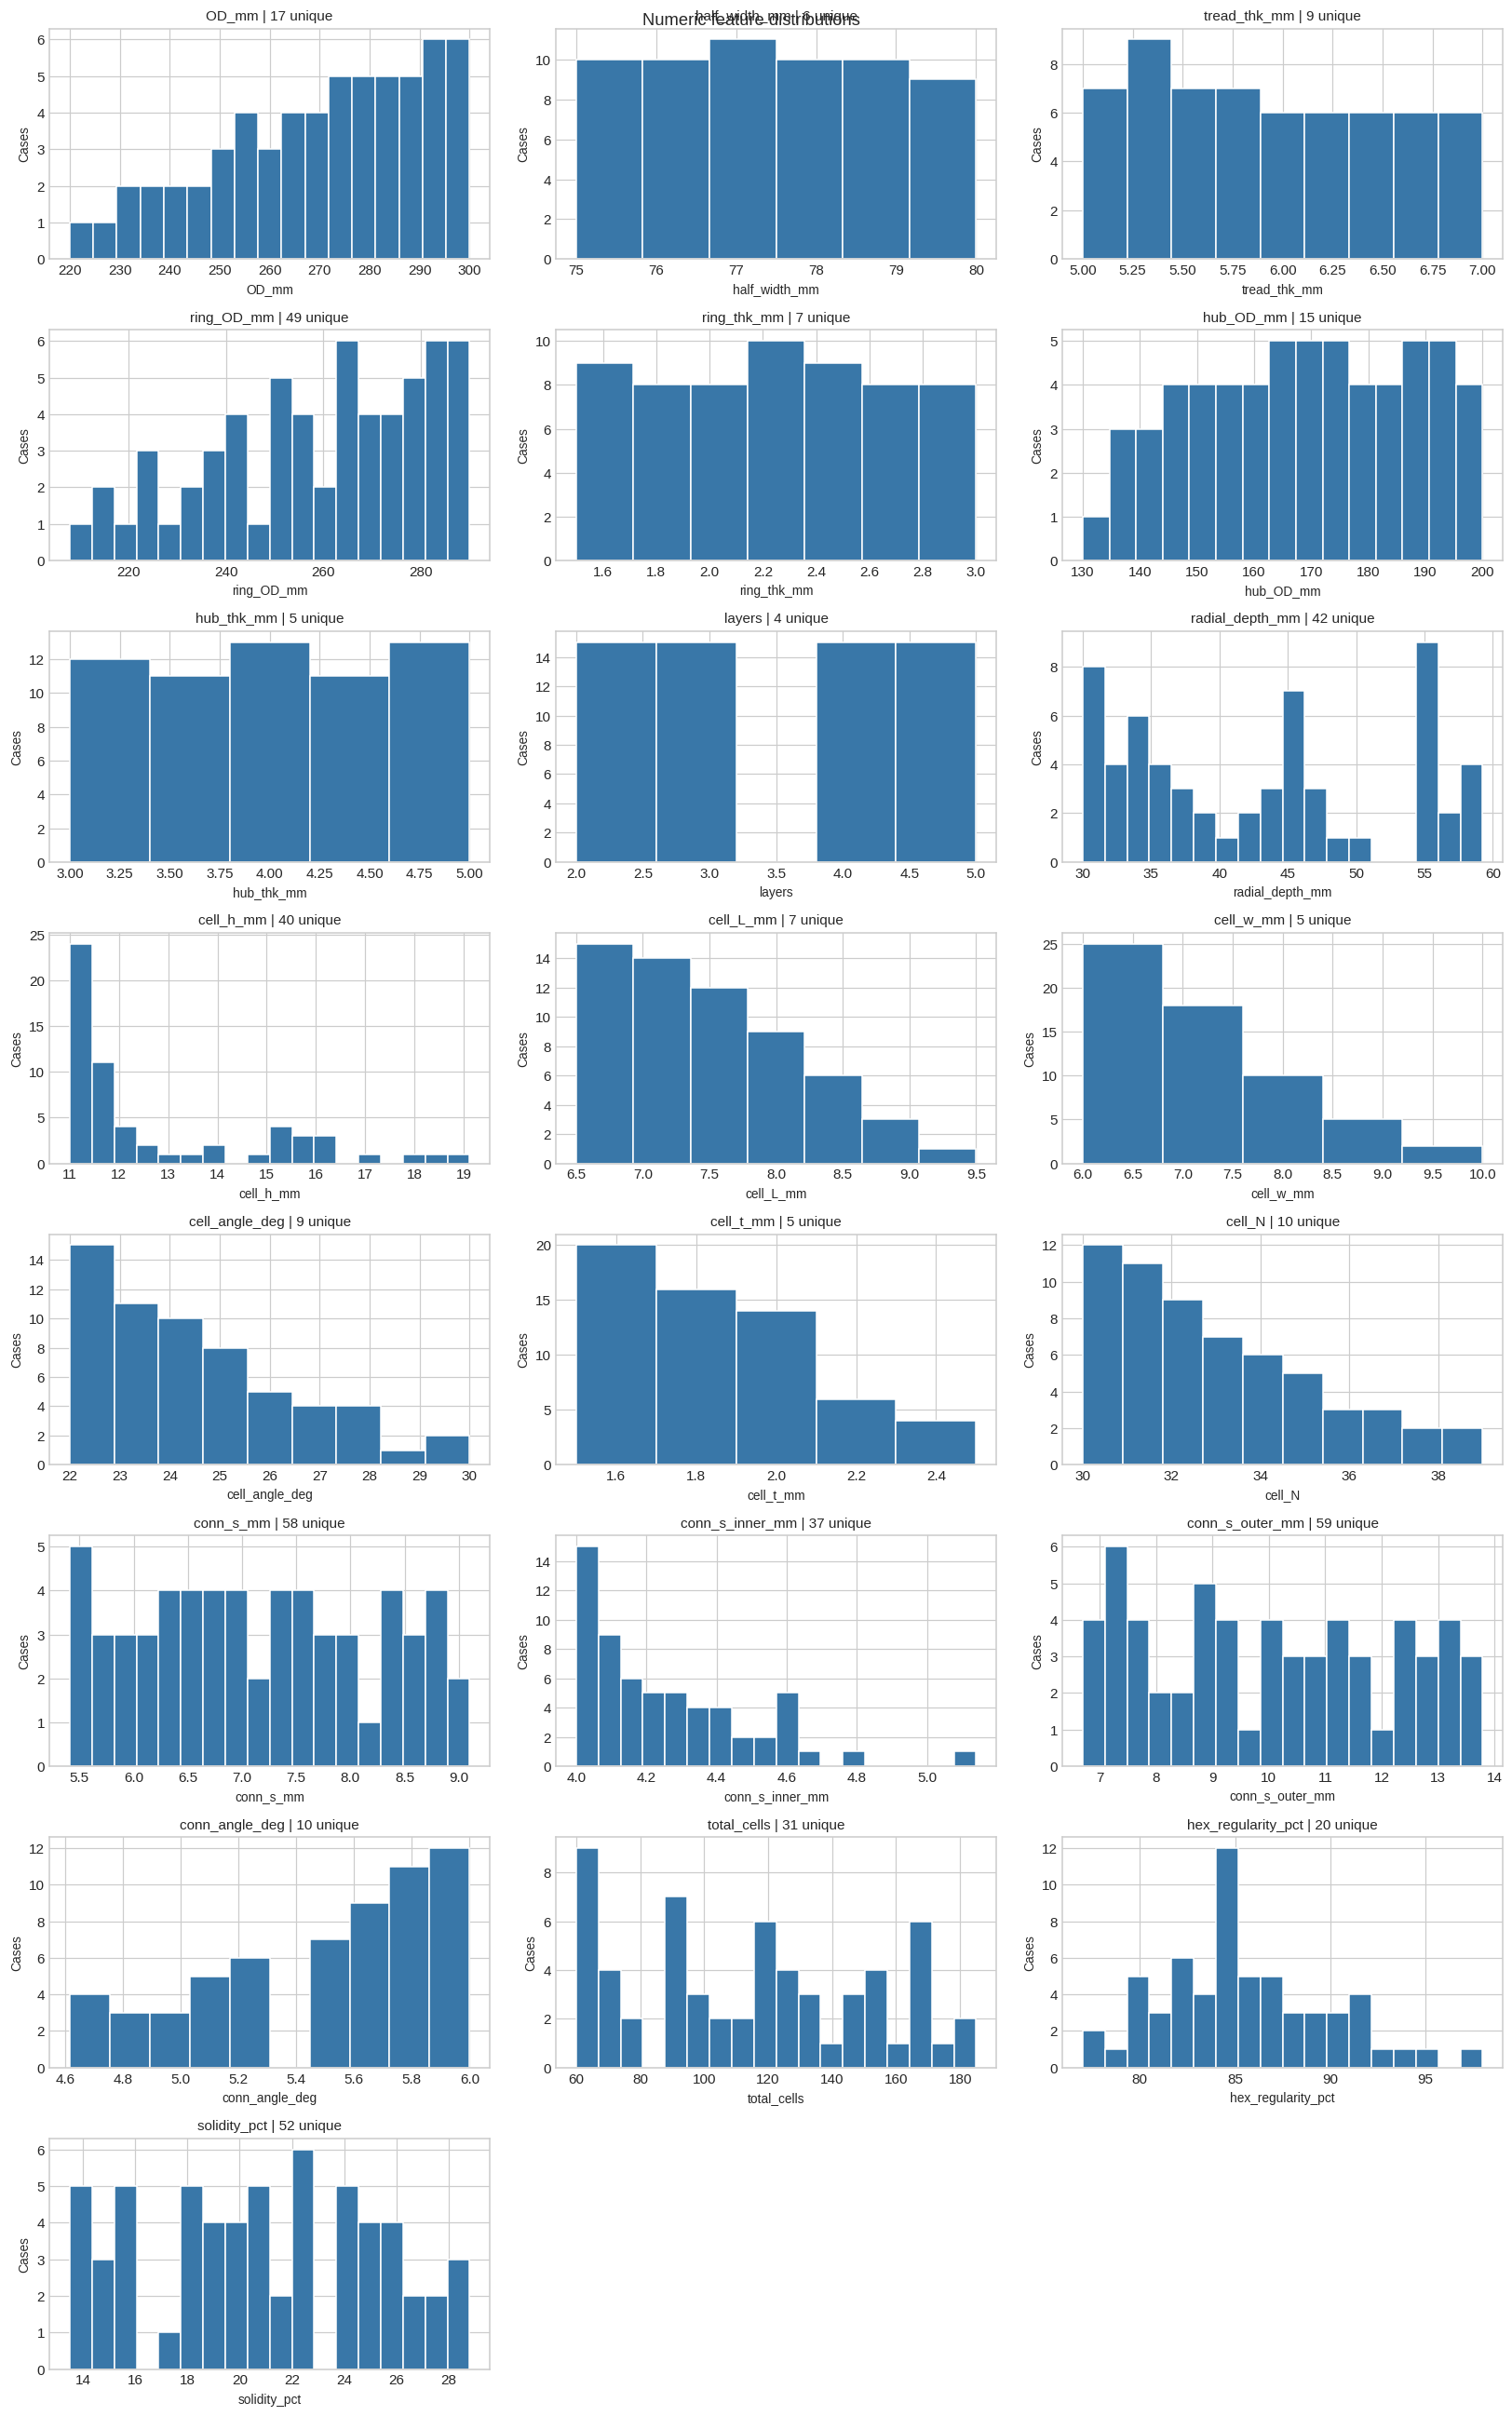

/tmp/ipykernel_91401/11396429.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  fig,ax=plt.subplots(figsize=(15,6)); ax.boxplot([z[c].dropna() for c in num_cols],labels=num_cols,showfliers=True); ax.axhline(0,color='black',lw=.7); ax.set_ylabel('z-score'); ax.tick_params(axis='x',rotation=75); ax.set_title('Standardized spread and potential outliers'); fig.tight_layout(); plt.show()


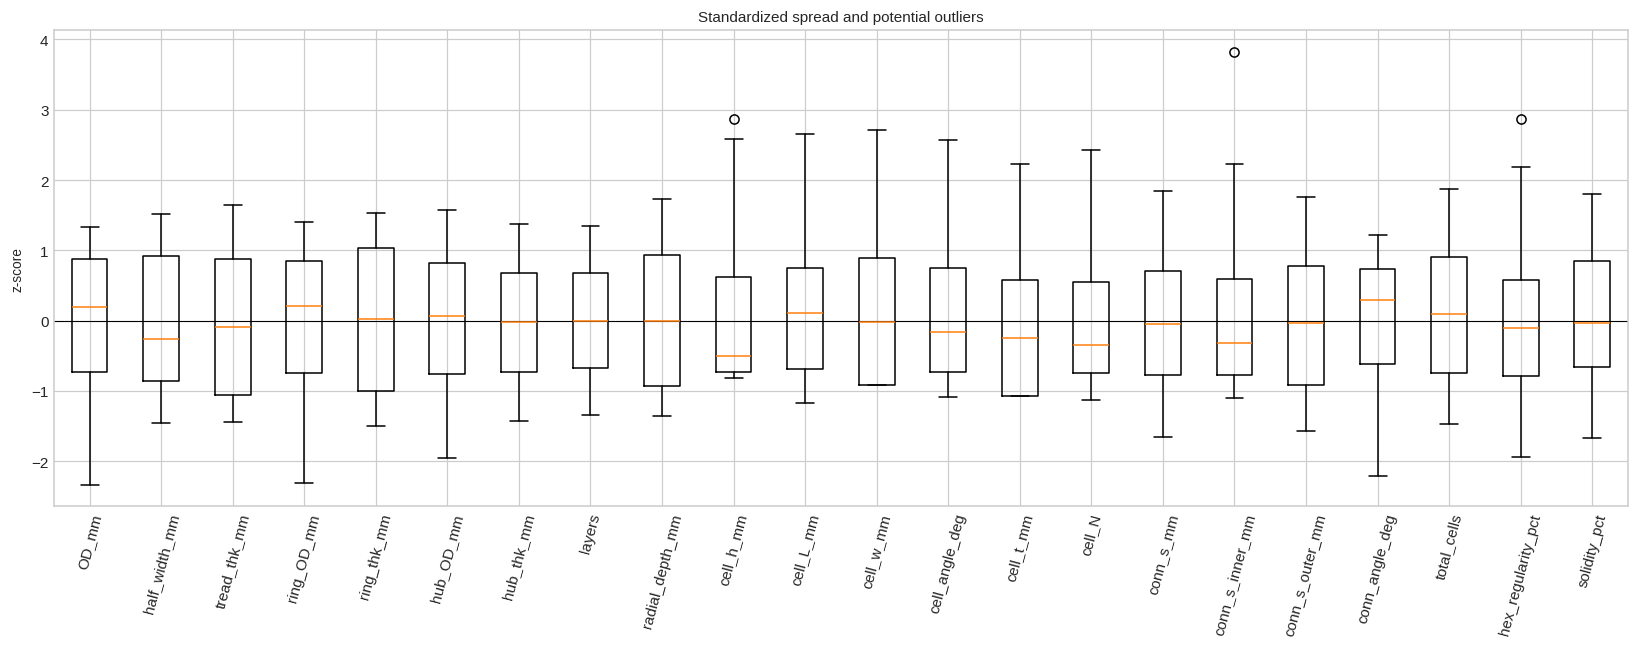

,flagged_rows,low_fence,high_fence
feature,,,
conn_s_inner_mm,1,3.599,4.869
cell_h_mm,1,6.696,18.686
hex_regularity_pct,1,73.000,97.000
tread_thk_mm,0,3.375,8.375
OD_mm,0,202.500,342.500
half_width_mm,0,71.500,83.500
hub_OD_mm,0,106.875,231.875
ring_thk_mm,0,0.250,4.250
ring_OD_mm,0,189.750,330.750


In [11]:
cols=3; rows=math.ceil(len(num_cols)/cols)
fig,axes=plt.subplots(rows,cols,figsize=(15,3*rows)); axes=np.asarray(axes).reshape(-1)
for ax,c in zip(axes,num_cols): ax.hist(df[c].dropna(),bins=min(18,max(5,df[c].nunique())),color='#3977a8',edgecolor='white'); ax.set_title(f'{c} | {df[c].nunique()} unique'); ax.set_xlabel(c); ax.set_ylabel('Cases')
for ax in axes[len(num_cols):]: ax.remove()
fig.suptitle('Numeric feature distributions'); fig.tight_layout(); plt.show()
z=(df[num_cols]-df[num_cols].mean())/df[num_cols].std(ddof=0).replace(0,np.nan)
fig,ax=plt.subplots(figsize=(15,6)); ax.boxplot([z[c].dropna() for c in num_cols],labels=num_cols,showfliers=True); ax.axhline(0,color='black',lw=.7); ax.set_ylabel('z-score'); ax.tick_params(axis='x',rotation=75); ax.set_title('Standardized spread and potential outliers'); fig.tight_layout(); plt.show()
out=[]
for c in num_cols:
 q1,q3=df[c].quantile([.25,.75]); iqr=q3-q1; mask=(df[c]<q1-1.5*iqr)|(df[c]>q3+1.5*iqr); out.append({'feature':c,'flagged_rows':int(mask.sum()),'low_fence':q1-1.5*iqr,'high_fence':q3+1.5*iqr})
display(pd.DataFrame(out).set_index('feature').sort_values('flagged_rows',ascending=False).round(3))

## 3. Pairwise association and strongest relationships

Pearson emphasizes linear association; Spearman uses ranks and captures monotonic trends. Strong correlations may indicate shared design constraints or derived columns. They can also destabilize feature importance. Validate any proposed feature removal with engineering definitions.

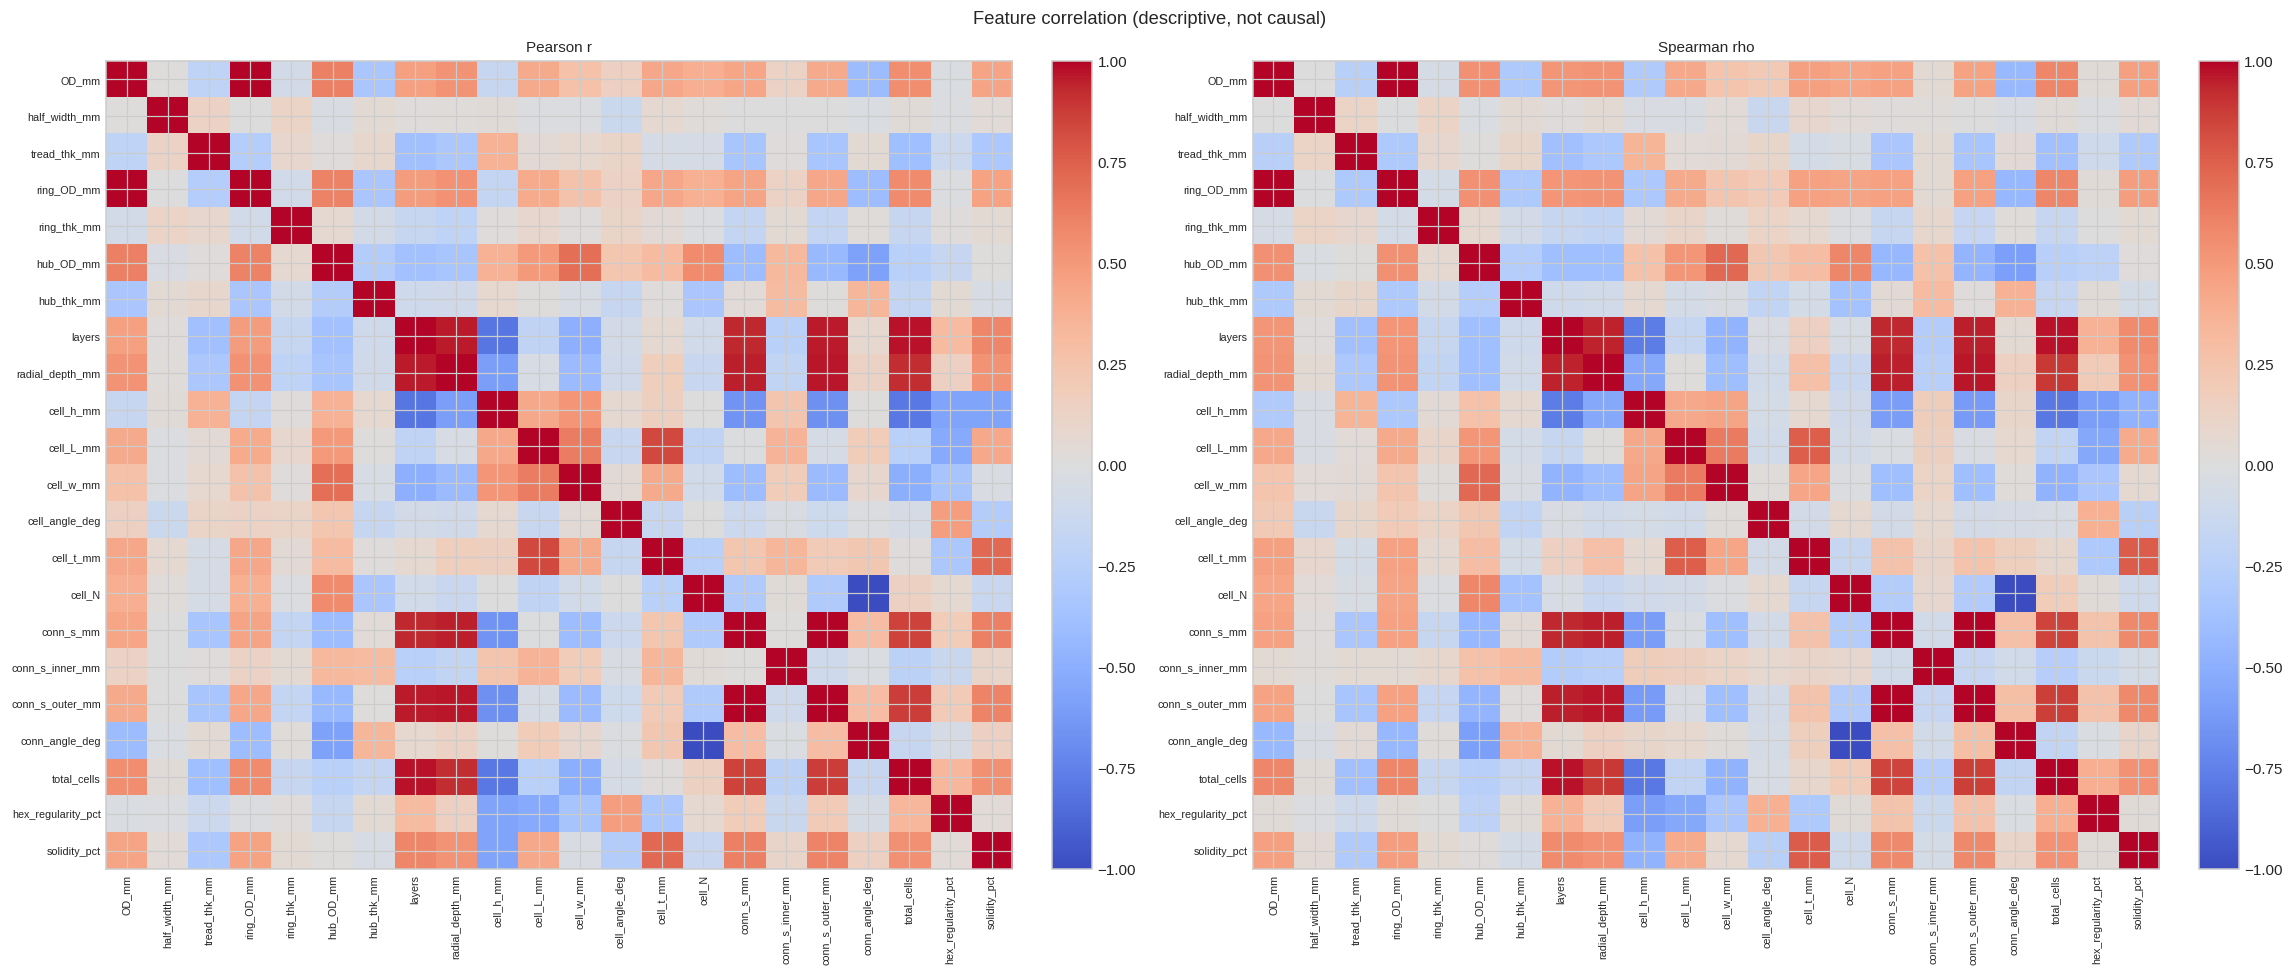

,feature_1,feature_2,pearson_r,spearman_r
2,OD_mm,ring_OD_mm,0.998,0.998
206,cell_N,conn_angle_deg,-0.997,-1.000
211,conn_s_mm,conn_s_outer_mm,0.994,0.994
137,layers,total_cells,0.973,0.970
148,radial_depth_mm,conn_s_outer_mm,0.968,0.965
126,layers,radial_depth_mm,0.955,0.939
135,layers,conn_s_outer_mm,0.954,0.949
146,radial_depth_mm,conn_s_mm,0.952,0.950
133,layers,conn_s_mm,0.934,0.936
150,radial_depth_mm,total_cells,0.915,0.885


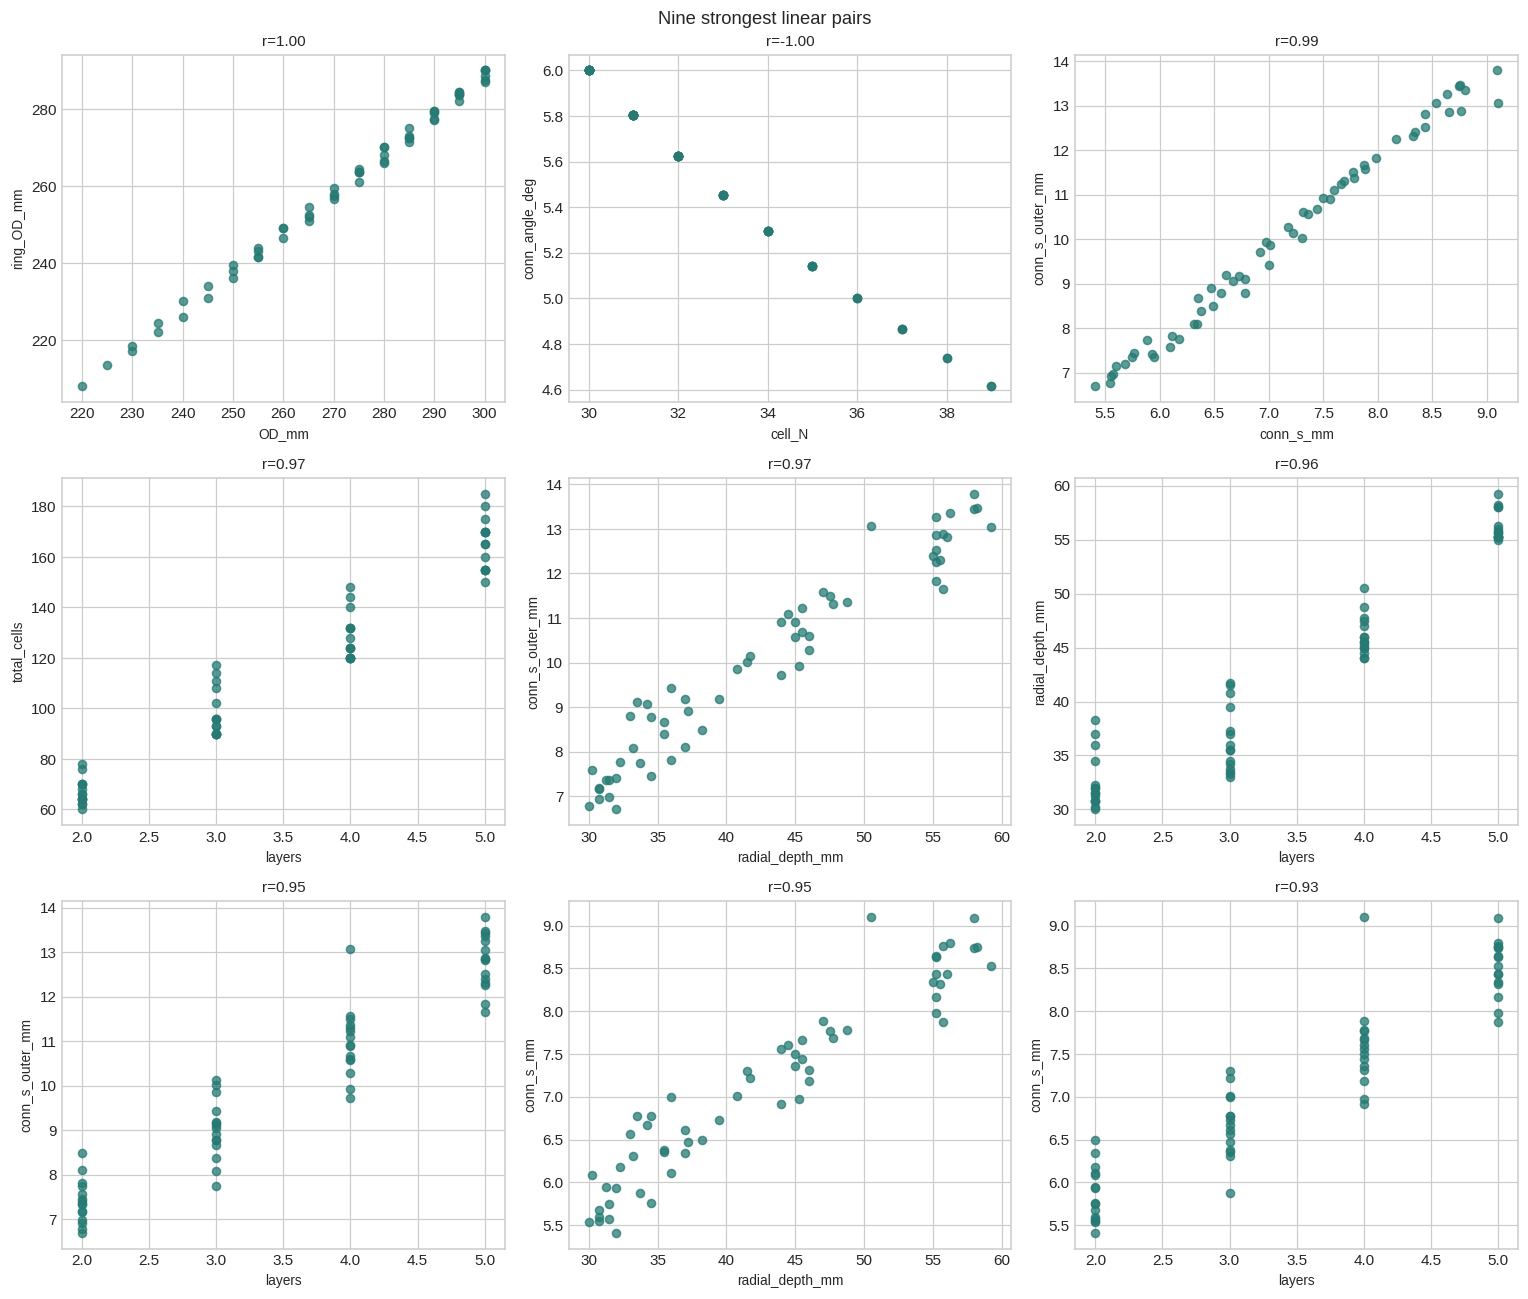

In [12]:
pearson=df[num_cols].corr(); spearman=df[num_cols].corr(method='spearman')
fig,axes=plt.subplots(1,2,figsize=(21,9))
for ax,mat,title in zip(axes,[pearson,spearman],['Pearson r','Spearman rho']):
 im=ax.imshow(mat,vmin=-1,vmax=1,cmap='coolwarm',aspect='auto'); ax.set_xticks(range(len(num_cols)),num_cols,rotation=90,fontsize=7); ax.set_yticks(range(len(num_cols)),num_cols,fontsize=7); ax.set_title(title); fig.colorbar(im,ax=ax,fraction=.046,pad=.04)
fig.suptitle('Feature correlation (descriptive, not causal)'); fig.tight_layout(); plt.show()
pairs=[{'feature_1':a,'feature_2':b,'pearson_r':pearson.loc[a,b],'spearman_r':spearman.loc[a,b]} for i,a in enumerate(num_cols) for b in num_cols[i+1:]]
pair_table=pd.DataFrame(pairs); display(pair_table.assign(abs_r=lambda x:x.pearson_r.abs()).sort_values('abs_r',ascending=False).drop(columns='abs_r').head(25).round(3))
top=pair_table.assign(abs_r=lambda x:x.pearson_r.abs()).nlargest(9,'abs_r')
fig,axes=plt.subplots(3,3,figsize=(14,12))
for ax,r in zip(axes.flat,top.itertuples()): ax.scatter(df[r.feature_1],df[r.feature_2],s=28,alpha=.75,color='#267a73'); ax.set_xlabel(r.feature_1); ax.set_ylabel(r.feature_2); ax.set_title(f'r={r.pearson_r:.2f}')
fig.suptitle('Nine strongest linear pairs'); fig.tight_layout(); plt.show()

## 4. Geometry and design-space views

Focused plots compare wheel diameters, radial depth, cell geometry, and cell counts. Color encodes a third design variable. These plots reveal clusters and tradeoffs; engineering meaning depends on the definitions of each field.

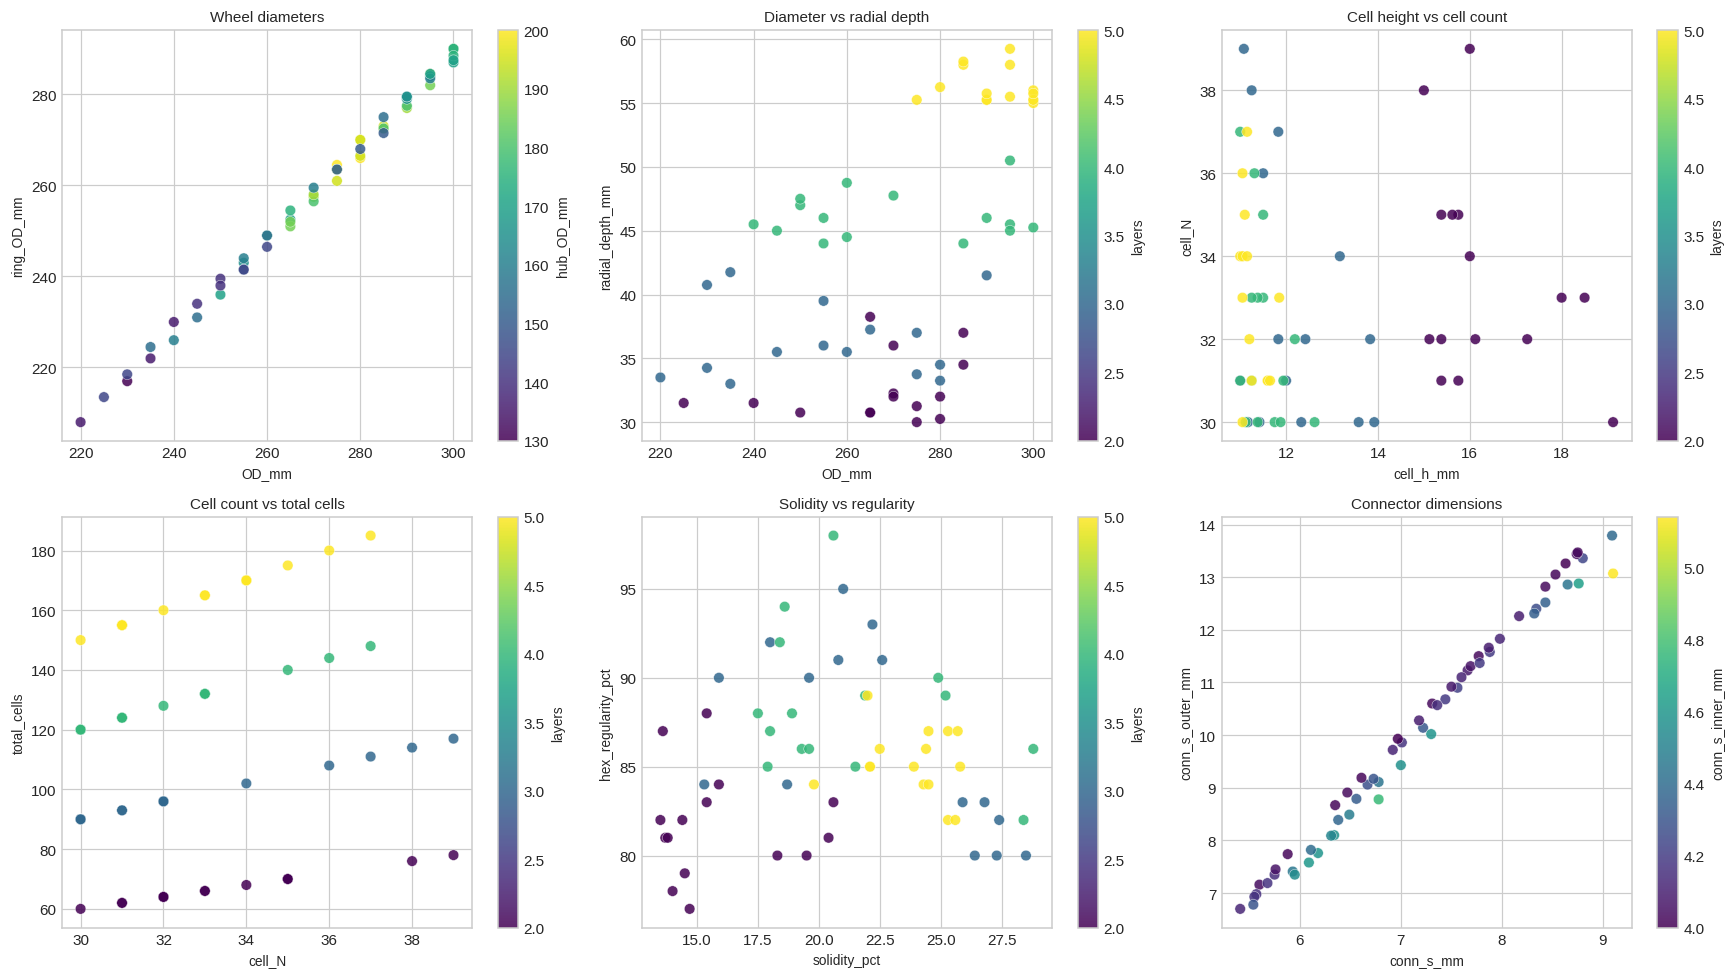

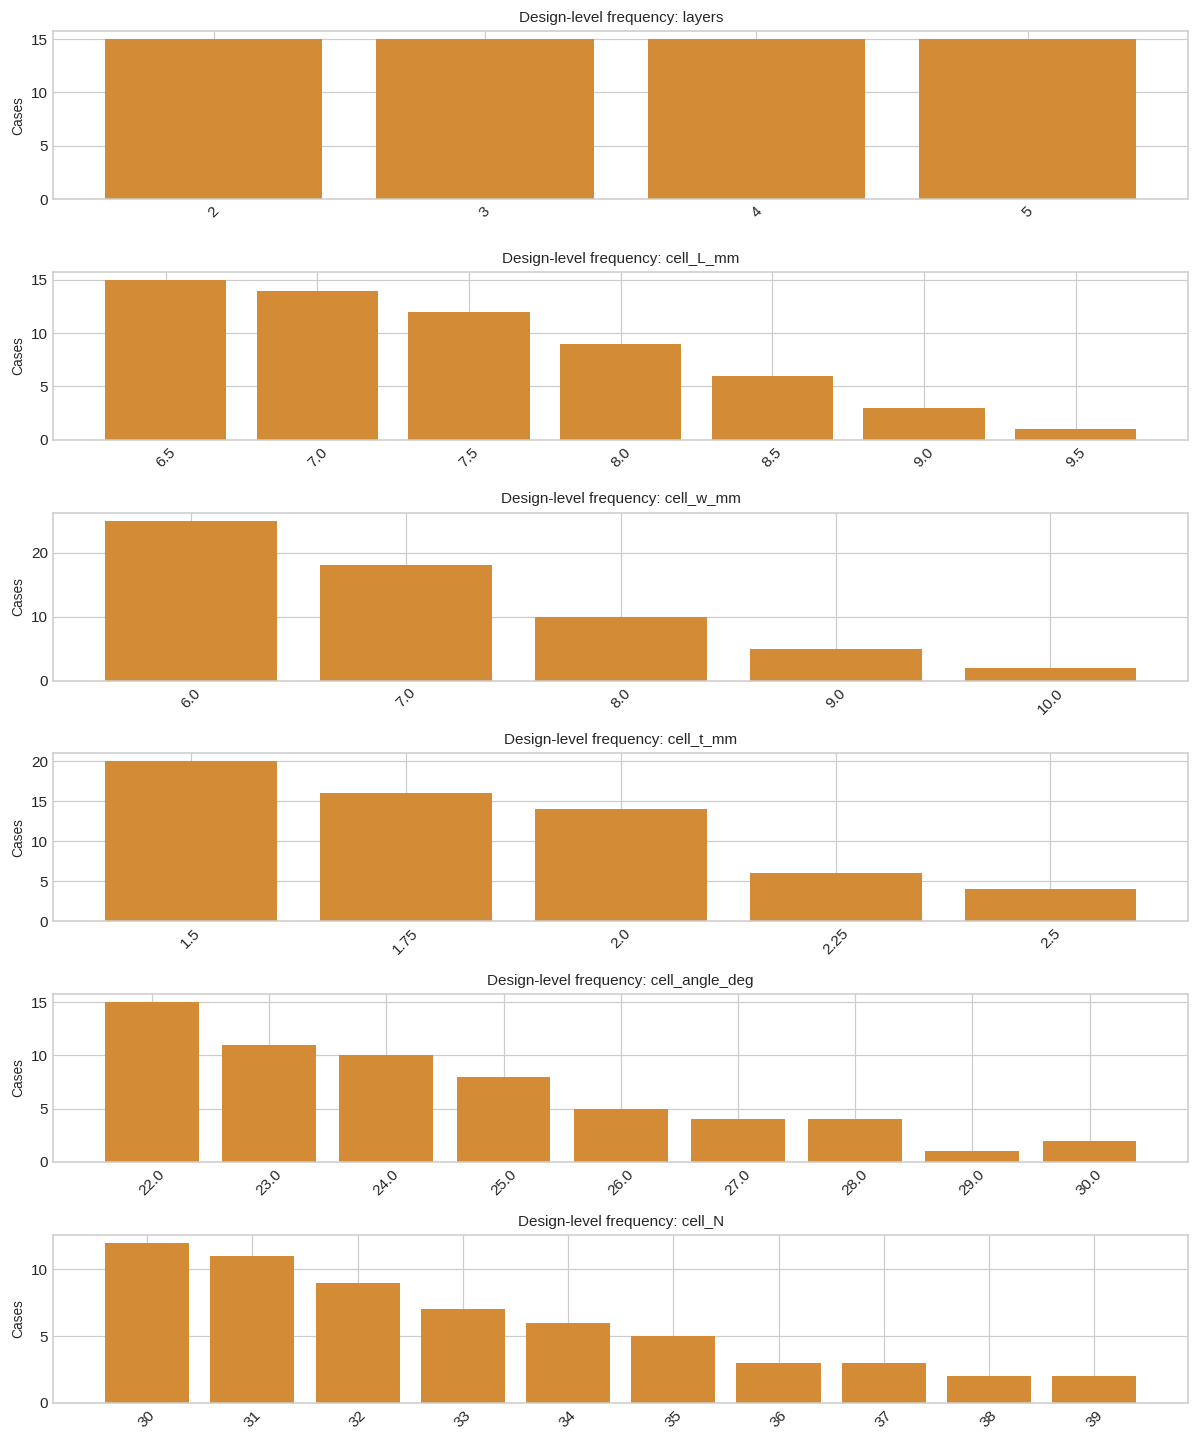

In [13]:
specs=[('OD_mm','ring_OD_mm','hub_OD_mm','Wheel diameters'),('OD_mm','radial_depth_mm','layers','Diameter vs radial depth'),('cell_h_mm','cell_N','layers','Cell height vs cell count'),('cell_N','total_cells','layers','Cell count vs total cells'),('solidity_pct','hex_regularity_pct','layers','Solidity vs regularity'),('conn_s_mm','conn_s_outer_mm','conn_s_inner_mm','Connector dimensions')]
fig,axes=plt.subplots(2,3,figsize=(16,9))
for ax,(x,y,c,title) in zip(axes.flat,specs):
 if {x,y,c} <= set(df):
  p=ax.scatter(df[x],df[y],c=df[c],cmap='viridis',s=48,alpha=.85,edgecolor='white',linewidth=.3); ax.set(xlabel=x,ylabel=y,title=title); fig.colorbar(p,ax=ax,label=c)
fig.tight_layout(); plt.show()
discrete=[c for c in ['layers','cell_L_mm','cell_w_mm','cell_t_mm','cell_angle_deg','cell_N'] if c in df]
fig,axes=plt.subplots(len(discrete),1,figsize=(11,2.2*len(discrete))); axes=np.atleast_1d(axes)
for ax,c in zip(axes,discrete): counts=df[c].value_counts().sort_index(); ax.bar(counts.index.astype(str),counts.values,color='#d38b36'); ax.set(title=f'Design-level frequency: {c}',ylabel='Cases'); ax.tick_params(axis='x',rotation=45)
fig.tight_layout(); plt.show()

## 5. Test candidate geometric identities

Names suggest possible formulas. Residual checks below are exploratory only; verify equations against the data dictionary or CAD logic. Near-zero residuals may reveal deterministic redundancy, while nonzero values may indicate a different definition or rounding.

In [14]:
checks=[]
def check(label,observed,expected):
 residual=(observed-expected).dropna(); checks.append({'candidate':label,'mean_abs_residual':residual.abs().mean(),'max_abs_residual':residual.abs().max(),'within_1e-6':int((residual.abs()<1e-6).sum()),'rows':len(residual)})
if {'OD_mm','tread_thk_mm','ring_OD_mm'}<=set(df): check('ring_OD ≈ OD - 2*tread thickness',df.ring_OD_mm,df.OD_mm-2*df.tread_thk_mm)
if {'ring_OD_mm','hub_OD_mm','radial_depth_mm'}<=set(df): check('radial_depth ≈ (ring_OD - hub_OD)/2',df.radial_depth_mm,(df.ring_OD_mm-df.hub_OD_mm)/2)
if {'conn_s_mm','conn_s_inner_mm','conn_s_outer_mm'}<=set(df): check('conn_s ≈ mean(inner, outer)',df.conn_s_mm,(df.conn_s_inner_mm+df.conn_s_outer_mm)/2)
if {'total_cells','layers','cell_N'}<=set(df): check('total_cells ≈ layers * cell_N',df.total_cells,df.layers*df.cell_N)
display(pd.DataFrame(checks).set_index('candidate').round(6) if checks else 'No candidate formulas available.')

,mean_abs_residual,max_abs_residual,within_1e-6,rows
candidate,,,,
ring_OD ≈ OD - 2*tread thickness,0.000000,0.000,60,60
radial_depth ≈ (ring_OD - hub_OD)/2,2.241667,3.000,0,60
"conn_s ≈ mean(inner, outer)",0.002750,0.005,27,60
total_cells ≈ layers * cell_N,0.000000,0.000,60,60


## 6. Identifier sequence diagnostics

A case ID may encode families or a sequence. Its suffix is treated only as a diagnostic. Row order or ID sequence should not be used as a model input unless it represents a real signal available at prediction time.

,cases
family,
HEX60,60


,spearman_r
total_cells,0.999
layers,0.968
radial_depth_mm,0.886
conn_s_outer_mm,0.864
conn_s_mm,0.852
cell_h_mm,-0.787
ring_OD_mm,0.608
OD_mm,0.599
solidity_pct,0.558
cell_w_mm,-0.444


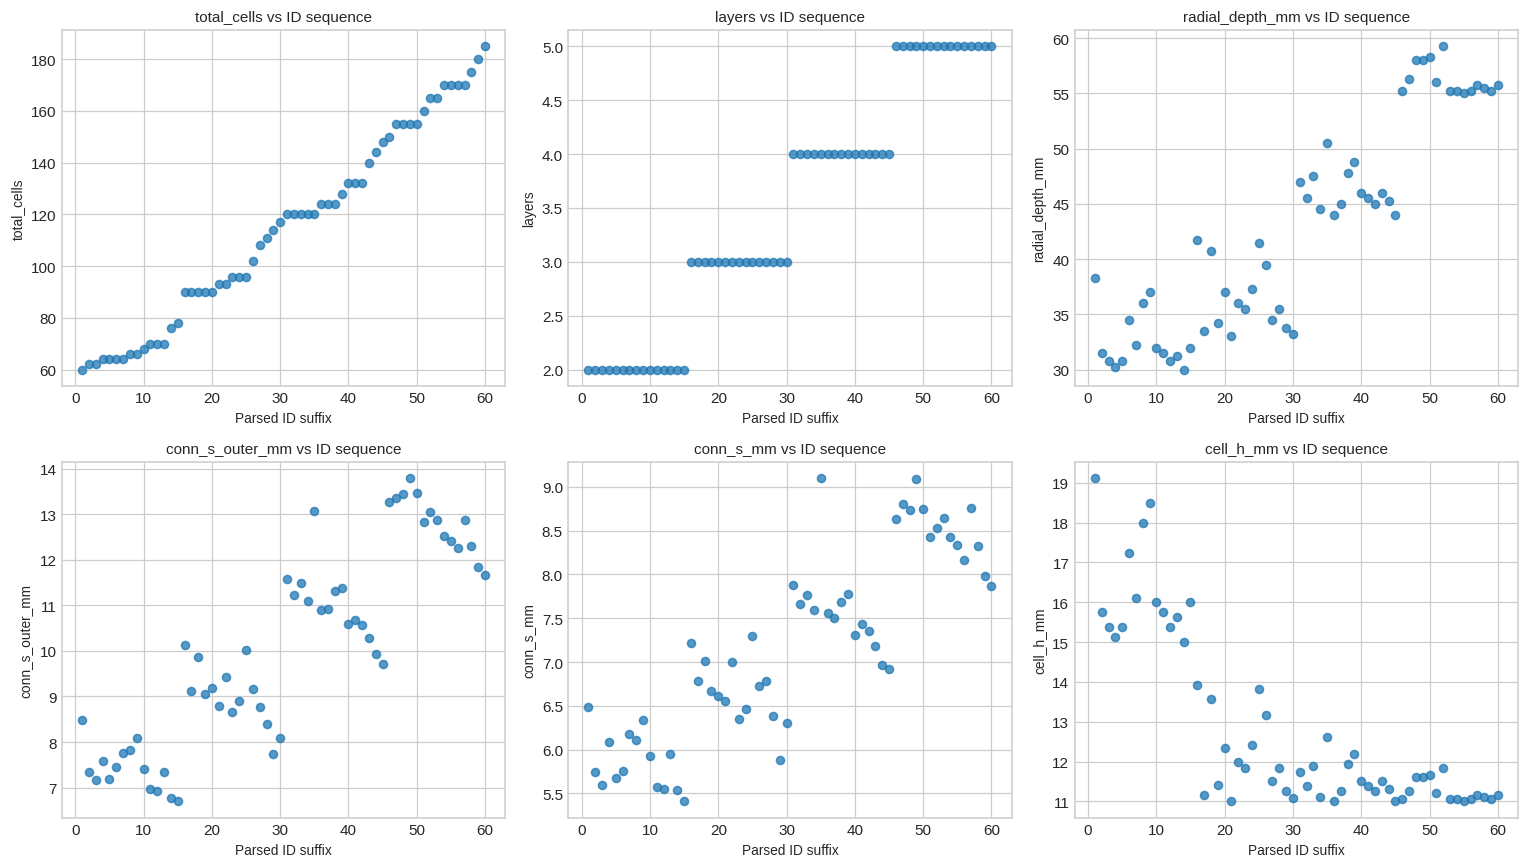

In [15]:
if 'case_id' in df:
 ids=df.case_id.astype(str).str.extract(r'^(?P<family>.*?)(?:[_-](?P<sequence>\d+))?$'); diag=df.copy(); diag['family']=ids.family.fillna('unknown'); diag['sequence']=pd.to_numeric(ids.sequence,errors='coerce')
 display(diag.family.value_counts().rename('cases').to_frame())
 if diag.sequence.notna().any():
  assoc=diag[['sequence']+num_cols].corr(method='spearman').sequence.drop('sequence').sort_values(key=lambda s:s.abs(),ascending=False); display(assoc.head(12).rename('spearman_r').to_frame().round(3))
  chosen=assoc.head(6).index.tolist(); fig,axes=plt.subplots(2,3,figsize=(14,8))
  for ax,c in zip(axes.flat,chosen): ax.scatter(diag.sequence,diag[c],s=28,alpha=.75); ax.set(xlabel='Parsed ID suffix',ylabel=c,title=f'{c} vs ID sequence')
  for ax in axes.flat[len(chosen):]: ax.remove()
  fig.tight_layout(); plt.show()
else: print('No case_id column; skipping ID diagnostics.')

## 7. Multivariate structure: PCA and exploratory clusters

PCA combines standardized numeric columns into orthogonal directions and helps visualize broad design-space variation. Loadings show which features contribute most to the leading components. K-means is only an exploratory grouping aid: results depend on scaling, selected features, and cluster count; they are not validated engineering categories.


,component,explained,cumulative
0,PC1,0.315,0.315
1,PC2,0.195,0.510
2,PC3,0.146,0.656
3,PC4,0.067,0.723
4,PC5,0.056,0.779
5,PC6,0.054,0.833
6,PC7,0.048,0.881
7,PC8,0.035,0.916
8,PC9,0.030,0.946
9,PC10,0.023,0.970


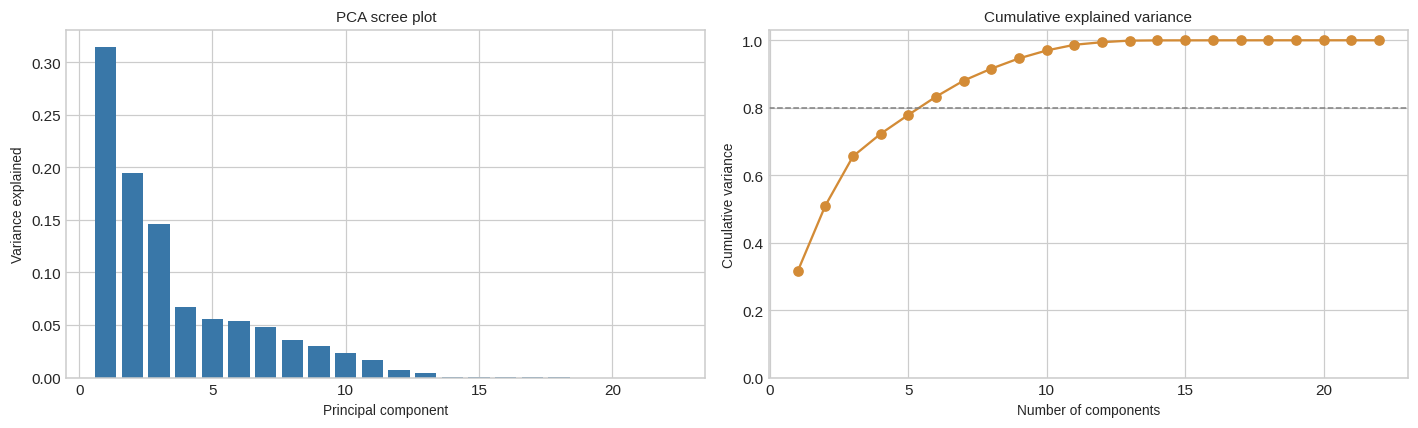

Largest absolute contributions to PC1_loading:


,absolute_loading,PC1_loading
layers,0.377,0.377
total_cells,0.366,0.366
conn_s_outer_mm,0.364,0.364
radial_depth_mm,0.362,0.362
conn_s_mm,0.360,0.360
cell_h_mm,0.301,-0.301
solidity_pct,0.250,0.250
ring_OD_mm,0.196,0.196


Largest absolute contributions to PC2_loading:


,absolute_loading,PC2_loading
hub_OD_mm,0.415,0.415
OD_mm,0.386,0.386
ring_OD_mm,0.383,0.383
cell_L_mm,0.367,0.367
cell_t_mm,0.324,0.324
cell_w_mm,0.308,0.308
solidity_pct,0.180,0.180
conn_angle_deg,0.179,-0.179


Largest absolute contributions to PC3_loading:


,absolute_loading,PC3_loading
conn_angle_deg,0.471,0.471
cell_N,0.471,-0.471
cell_t_mm,0.330,0.330
cell_L_mm,0.314,0.314
hub_thk_mm,0.243,0.243
hex_regularity_pct,0.222,-0.222
solidity_pct,0.196,0.196
hub_OD_mm,0.182,-0.182


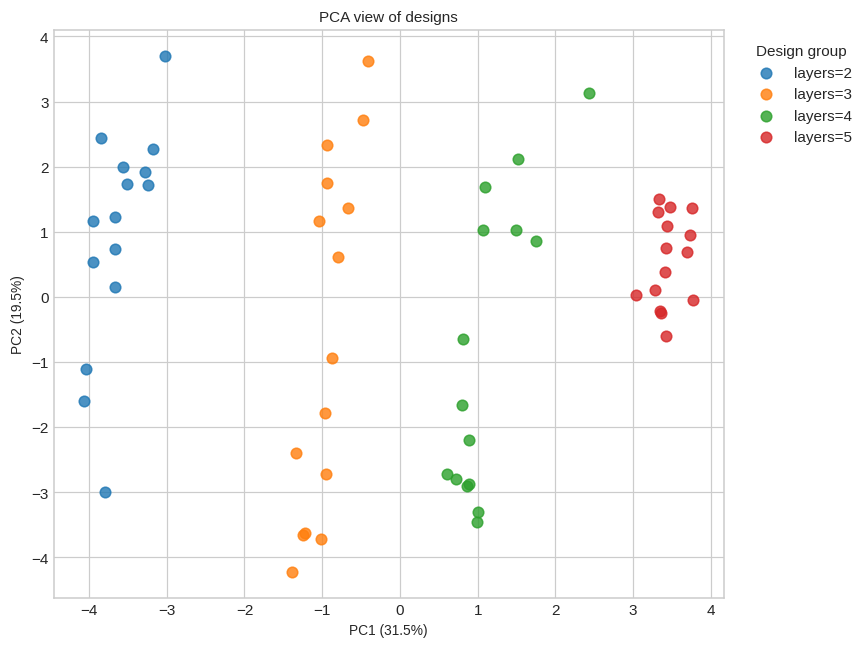

,k,silhouette,smallest_cluster
2,4,0.238,8
1,3,0.234,17
3,5,0.219,8
0,2,0.211,30
4,6,0.205,6


Exploratory K-means profiles for k=4; compare with known design families before interpreting.


cluster,0,1,2,3
OD_mm,291.19,243.12,275.00,270.00
half_width_mm,77.38,77.50,77.25,77.60
tread_thk_mm,5.67,5.98,5.94,6.25
ring_OD_mm,279.86,231.16,263.12,257.50
ring_thk_mm,2.19,2.27,2.22,2.30
hub_OD_mm,169.05,144.38,181.25,188.00
hub_thk_mm,3.79,4.34,4.50,3.73
layers,4.71,3.44,2.75,2.27
radial_depth_mm,53.21,41.12,38.72,32.45
cell_h_mm,11.29,12.12,14.62,14.70


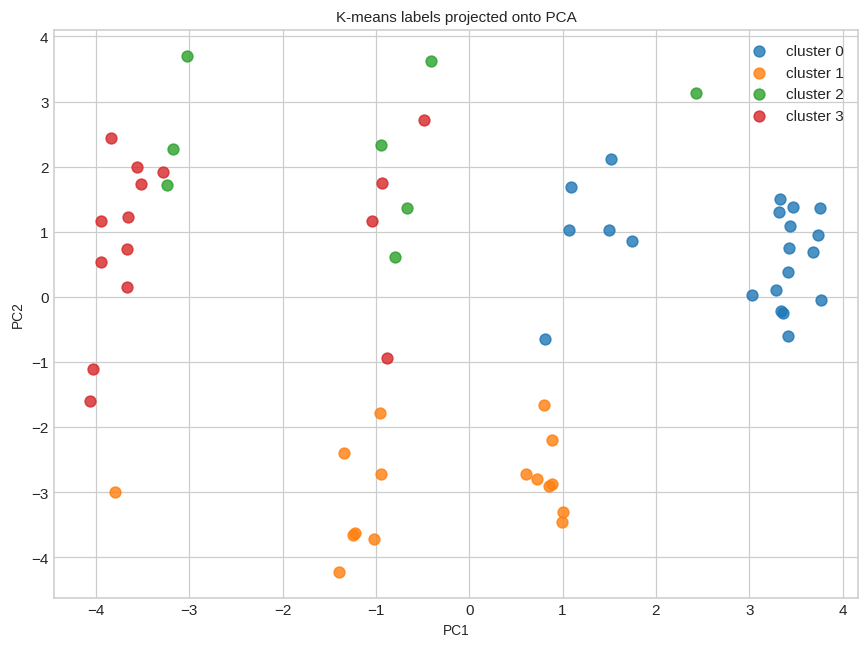

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Imputation keeps this analysis usable if a future dataset version contains gaps.
X_numeric = df[num_cols].apply(lambda s: s.fillna(s.median()))
X_scaled = StandardScaler().fit_transform(X_numeric)
pca = PCA().fit(X_scaled)
variance = pd.DataFrame({'component':[f'PC{i+1}' for i in range(len(num_cols))],
                         'explained':pca.explained_variance_ratio_,
                         'cumulative':np.cumsum(pca.explained_variance_ratio_)})
display(variance.head(12).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(np.arange(1, len(num_cols)+1), pca.explained_variance_ratio_, color='#3977a8')
axes[0].set(xlabel='Principal component', ylabel='Variance explained', title='PCA scree plot')
axes[1].plot(np.arange(1, len(num_cols)+1), np.cumsum(pca.explained_variance_ratio_), marker='o', color='#d38b36')
axes[1].axhline(.8, color='gray', ls='--', lw=1)
axes[1].set(ylim=(0, 1.03), xlabel='Number of components', ylabel='Cumulative variance', title='Cumulative explained variance')
fig.tight_layout(); plt.show()
scores = pca.transform(X_scaled)
loadings = pd.DataFrame(pca.components_[:3].T, index=num_cols, columns=['PC1_loading','PC2_loading','PC3_loading'])
for pc in loadings.columns:
    print(f'Largest absolute contributions to {pc}:')
    display(loadings[pc].abs().sort_values(ascending=False).head(8).to_frame('absolute_loading').join(loadings[pc]).round(3))
fig, ax = plt.subplots(figsize=(8, 6))
if 'layers' in df:
    for layer in sorted(df.layers.dropna().unique()):
        mask = df.layers == layer
        ax.scatter(scores[mask, 0], scores[mask, 1], s=48, alpha=.8, label=f'layers={layer}')
    ax.legend(title='Design group', bbox_to_anchor=(1.02, 1), loc='upper left')
else:
    ax.scatter(scores[:, 0], scores[:, 1], s=48, alpha=.8)
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})', title='PCA view of designs')
fig.tight_layout(); plt.show()

cluster_rows, cluster_models = [], {}
for k in range(2, min(7, len(df)-1)):
    km = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X_scaled)
    labels = km.labels_
    if len(np.unique(labels)) > 1:
        cluster_rows.append({'k':k, 'silhouette':silhouette_score(X_scaled, labels),
                             'smallest_cluster':int(pd.Series(labels).value_counts().min())})
        cluster_models[k] = (km, labels)
cluster_scores = pd.DataFrame(cluster_rows).sort_values('silhouette', ascending=False)
display(cluster_scores.round(3))
if len(cluster_scores):
    best_k = int(cluster_scores.iloc[0]['k'])
    km, labels = cluster_models[best_k]
    cluster_profile = df[num_cols].assign(cluster=labels).groupby('cluster').mean()
    print(f'Exploratory K-means profiles for k={best_k}; compare with known design families before interpreting.')
    display(cluster_profile.T.round(2))
    fig, ax = plt.subplots(figsize=(8, 6))
    for label in sorted(np.unique(labels)):
        mask = labels == label
        ax.scatter(scores[mask, 0], scores[mask, 1], s=50, alpha=.8, label=f'cluster {label}')
    ax.set(xlabel='PC1', ylabel='PC2', title='K-means labels projected onto PCA')
    ax.legend(); fig.tight_layout(); plt.show()


## 8. Design coverage and within-group variation

Count combinations of key discrete controls and compare selected geometry metrics across layer groups. Sparse combinations indicate parts of the design space with little coverage. Group differences are descriptive and may reflect correlated settings.


60 distinct combinations across 6 selected controls; most common:


,layers,cell_N,cell_L_mm,cell_w_mm,cell_t_mm,cell_angle_deg,cases
45,5,30,7.5,7.0,2.00,23.0,1
46,5,31,7.5,6.0,2.00,24.0,1
47,5,31,7.5,6.0,2.00,25.0,1
48,5,31,7.5,7.0,2.00,23.0,1
49,5,31,8.0,7.0,2.00,24.0,1
50,5,32,8.0,7.0,2.00,25.0,1
51,5,33,7.5,6.0,2.00,25.0,1
52,5,33,7.5,6.0,2.00,29.0,1
53,5,34,7.0,6.0,1.75,25.0,1
54,5,34,7.0,7.0,1.75,25.0,1


Singleton combinations: 60

radial_depth_mm by layer count:


,count,mean,std,min,median,max
layers,,,,,,
2,15,32.583,2.592,30.0,31.50,38.25
3,15,36.467,3.060,33.0,35.50,41.75
4,15,46.150,1.834,44.0,45.50,50.50
5,15,56.267,1.384,55.0,55.75,59.25



total_cells by layer count:


...


solidity_pct by layer count:


,count,mean,std,min,median,max
layers,,,,,,
2,15,15.847,2.551,13.5,14.7,20.6
3,15,22.427,4.408,15.3,22.2,28.5
4,15,21.300,3.789,17.5,19.6,28.8
5,15,23.853,1.765,19.8,24.4,25.8



cell_h_mm by layer count:


,count,mean,std,min,median,max
layers,,,,,,
2,15,16.291,1.295,15.0,15.75,19.12
3,15,12.155,1.020,11.0,11.83,13.92
4,15,11.538,0.459,11.0,11.38,12.62
5,15,11.253,0.277,11.0,11.15,11.85


/tmp/ipykernel_91401/3670698980.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels)
/tmp/ipykernel_91401/3670698980.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels)
/tmp/ipykernel_91401/3670698980.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=labels)


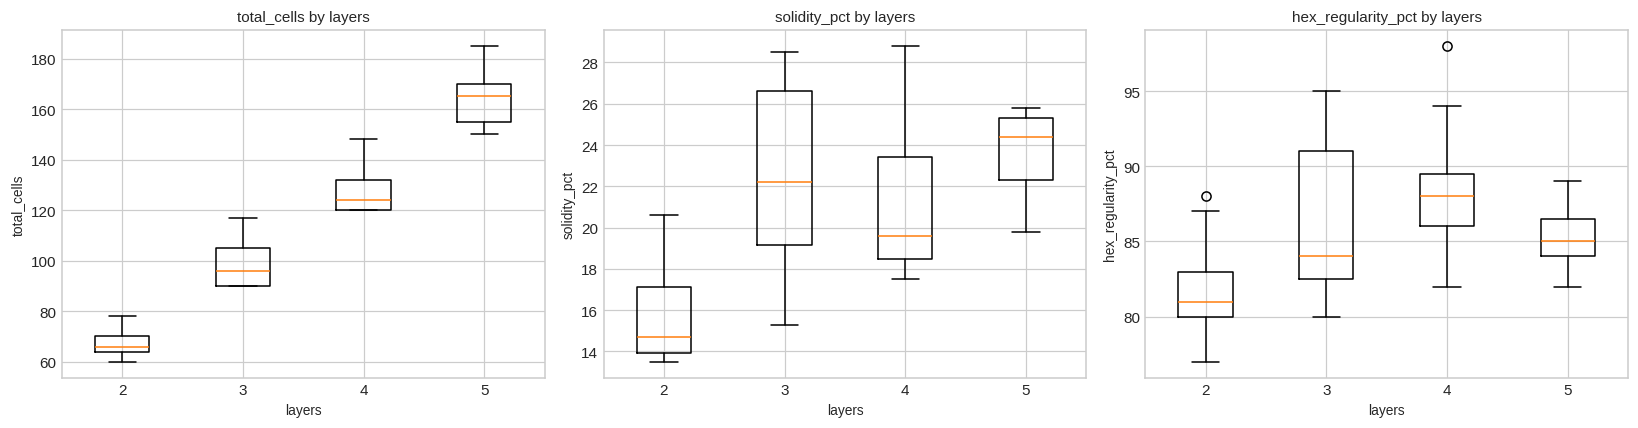

In [17]:
combination_cols = [c for c in ['layers','cell_N','cell_L_mm','cell_w_mm','cell_t_mm','cell_angle_deg'] if c in df]
if combination_cols:
    combo_counts = df.groupby(combination_cols, dropna=False).size().rename('cases').reset_index().sort_values('cases')
    print(f'{len(combo_counts)} distinct combinations across {len(combination_cols)} selected controls; most common:')
    display(combo_counts.tail(15).sort_values('cases', ascending=False))
    print('Singleton combinations:', int((combo_counts.cases == 1).sum()))
if 'layers' in df:
    for feature in [c for c in ['radial_depth_mm','total_cells','hex_regularity_pct','solidity_pct','cell_h_mm'] if c in df]:
        print(f'\n{feature} by layer count:')
        display(df.groupby('layers')[feature].agg(['count','mean','std','min','median','max']).round(3))
    available = [c for c in ['total_cells','solidity_pct','hex_regularity_pct'] if c in df]
    fig, axes = plt.subplots(1, len(available), figsize=(5*len(available), 4))
    axes = np.atleast_1d(axes)
    for ax, feature in zip(axes, available):
        groups = [g[feature].dropna().values for _, g in df.groupby('layers')]
        labels = [str(k) for k, _ in df.groupby('layers')]
        ax.boxplot(groups, labels=labels)
        ax.set(xlabel='layers', ylabel=feature, title=f'{feature} by layers')
    fig.tight_layout(); plt.show()


## 9. Similar designs and isolated cases

Nearest-neighbor distances use standardized numeric features. A large distance means a case is less similar to the other sampled designs under this feature set and Euclidean metric. It is not a data-quality or engineering-defect score.


,case_id,nearest_other_id,nearest_distance,second_neighbor_distance
34,HEX60_35,HEX60_49,4.581,4.944
26,HEX60_27,HEX60_29,4.577,4.617
29,HEX60_30,HEX60_43,4.279,4.317
0,HEX60_01,HEX60_08,4.267,4.310
1,HEX60_02,HEX60_16,4.198,4.490
21,HEX60_22,HEX60_25,4.083,4.246
9,HEX60_10,HEX60_14,4.033,4.617
28,HEX60_29,HEX60_43,3.988,4.285
7,HEX60_08,HEX60_07,3.969,3.982
3,HEX60_04,HEX60_13,3.875,4.089


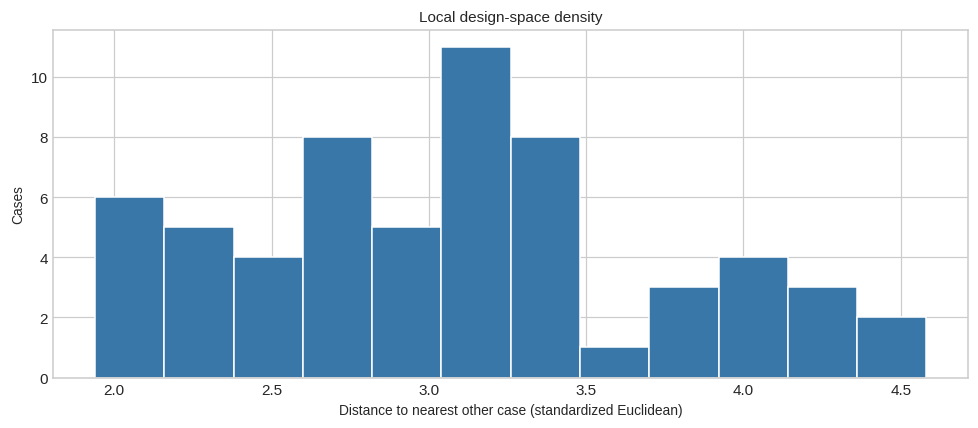

,distance,case_1,case_2
0,1.939,HEX60_46,HEX60_50
1,2.014,HEX60_54,HEX60_58
2,2.142,HEX60_32,HEX60_37
3,2.241,HEX60_47,HEX60_48
4,2.281,HEX60_55,HEX60_58
5,2.301,HEX60_33,HEX60_37
6,2.318,HEX60_48,HEX60_52
7,2.388,HEX60_49,HEX60_50
8,2.487,HEX60_48,HEX60_51
9,2.506,HEX60_54,HEX60_59


In [18]:
from sklearn.neighbors import NearestNeighbors
nn = NearestNeighbors(n_neighbors=min(4, len(df)), metric='euclidean').fit(X_scaled)
distances, indices = nn.kneighbors(X_scaled)
ids = df['case_id'].astype(str).to_numpy() if 'case_id' in df else df.index.astype(str).to_numpy()
nn_table = pd.DataFrame({'case_id':ids, 'nearest_other_id':ids[indices[:,1]],
                         'nearest_distance':distances[:,1],
                         'second_neighbor_distance':distances[:,2] if distances.shape[1] > 2 else np.nan})
display(nn_table.sort_values('nearest_distance', ascending=False).head(12).round(3))
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(nn_table.nearest_distance, bins=12, color='#3977a8', edgecolor='white')
ax.set(xlabel='Distance to nearest other case (standardized Euclidean)', ylabel='Cases', title='Local design-space density')
fig.tight_layout(); plt.show()
closest = []
for i in range(len(df)):
    for pos, j in enumerate(indices[i, 1:], start=1):
        if i < j:
            closest.append((distances[i, pos], i, j))
closest = sorted(closest)[:12]
display(pd.DataFrame([{'distance':d, 'case_1':ids[i], 'case_2':ids[j]} for d,i,j in closest]).round(3))


## 10. Summary and modeling considerations

Use the live tables below as the dataset-specific summary. The checklist focuses on preparation for the eventual supervised task, once target measurements are supplied.

In [19]:
print(f'{len(df)} cases, {len(num_cols)} numeric columns, {len(cat_cols)} non-numeric columns')
print(f'Missing cells: {int(df.isna().sum().sum())}; exact duplicate rows: {int(df.duplicated().sum())}')
display(pd.DataFrame({'min':df[num_cols].min(),'median':df[num_cols].median(),'max':df[num_cols].max(),'std':df[num_cols].std()}).round(3))
strong=pair_table[pair_table.pearson_r.abs()>=.90].sort_values('pearson_r',key=lambda s:s.abs(),ascending=False)
print(f'Pairs with |Pearson r| >= 0.90: {len(strong)}'); display(strong.round(3) if len(strong) else 'None at this threshold.')
print('\nNext steps when target measurements are available:')
print('• Confirm target definitions, units, and measurement quality.')
print('• Exclude case identifiers unless they encode a legitimate deployable signal.')
print('• Verify any deterministic geometric relationships before interpreting feature importance.')
print('• Consider group-aware splits if designs share families, batches, or repeated configurations.')
print('• Review each target metric separately; aggregate scores can conceal a weak target.')

60 cases, 22 numeric columns, 1 non-numeric columns
Missing cells: 0; exact duplicate rows: 0


,min,median,max,std
OD_mm,220.000,275.000,300.00,22.007
half_width_mm,75.000,77.000,80.00,1.692
tread_thk_mm,5.000,5.875,7.00,0.654
ring_OD_mm,208.000,263.500,290.00,22.319
ring_thk_mm,1.500,2.250,3.00,0.498
hub_OD_mm,130.000,170.000,200.00,19.987
hub_thk_mm,3.000,4.000,5.00,0.719
layers,2.000,3.500,5.00,1.127
radial_depth_mm,30.000,42.875,59.25,9.527
cell_h_mm,11.000,11.700,19.12,2.221


Pairs with |Pearson r| >= 0.90: 10


,feature_1,feature_2,pearson_r,spearman_r
2,OD_mm,ring_OD_mm,0.998,0.998
206,cell_N,conn_angle_deg,-0.997,-1.000
211,conn_s_mm,conn_s_outer_mm,0.994,0.994
137,layers,total_cells,0.973,0.970
148,radial_depth_mm,conn_s_outer_mm,0.968,0.965
126,layers,radial_depth_mm,0.955,0.939
135,layers,conn_s_outer_mm,0.954,0.949
146,radial_depth_mm,conn_s_mm,0.952,0.950
133,layers,conn_s_mm,0.934,0.936
150,radial_depth_mm,total_cells,0.915,0.885



Next steps when target measurements are available:
• Confirm target definitions, units, and measurement quality.
• Exclude case identifiers unless they encode a legitimate deployable signal.
• Verify any deterministic geometric relationships before interpreting feature importance.
• Consider group-aware splits if designs share families, batches, or repeated configurations.
• Review each target metric separately; aggregate scores can conceal a weak target.
